In [18]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import json
import os
from dotenv import load_dotenv

load_dotenv()
client_id = os.getenv("FROST_CLIENT_ID")
client_secret = os.getenv("FROST_CLIENT_SECRET")


In [19]:
def get_weather_data(
    station_id: str,
    elements: str,
    start_date: str,
    end_date: str,
) -> pd.DataFrame:
    """
    Fetch selected weather observations from Frost API.

    Args:
        station_id: Frost station ID, e.g. "SN18700".
        elements: Measurement element ID, e.g. "air_temperature".
        start_date: Start date in YYYY-MM-DD format.
        end_date: End date in YYYY-MM-DD format.

    Returns:
        A DataFrame containing the requested observations.

    Raises:
        ValueError: If the Frost Client ID is missing.
        requests.HTTPError: If the API request fails.
        requests.RequestException: If a connection error occurs.
    """
    if not client_id:
        raise ValueError("FROST_CLIENT_ID was not found.")

    url = "https://frost.met.no/observations/v0.jsonld"

    params = {
        "sources": station_id,
        "elements": elements,
        "referencetime": f"{start_date}/{end_date}",
    }

    response = requests.get(
        url,
        auth=(client_id, ""),
        params=params,
        timeout=30,
    )
    response.raise_for_status()

    data = response.json()["data"]

    if not data:
        return pd.DataFrame()

    df = pd.json_normalize(
        data,
        record_path="observations",
        meta=["sourceId", "referenceTime"],
    )

    return df


Task 1: Temperature

In [20]:
# Fetching weather data for 2025 from Frost API
df_2025 = get_weather_data(
    station_id="SN17850",
    elements="mean(air_temperature P1D)",
    start_date="2025-01-01",
    end_date="2025-12-31",
)

# Keep the recommended time offset for daily mean temperature
df_2025 = df_2025[
    df_2025["timeOffset"] == "PT0H"
].copy()

display(df_2025.head())


,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,level.levelType,level.unit,level.value,sourceId,referenceTime
0,mean(air_temperature P1D),-5.2,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-01T00:00:00.000Z
2,mean(air_temperature P1D),-11.5,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-02T00:00:00.000Z
4,mean(air_temperature P1D),-8.9,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-03T00:00:00.000Z
6,mean(air_temperature P1D),-15.5,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-04T00:00:00.000Z
8,mean(air_temperature P1D),-12.5,degC,PT0H,P1D,0,C,1,0.0,height_above_ground,m,2,SN17850:0,2025-01-05T00:00:00.000Z


According to the Frost API Data Clarifications, PT0H is the preferred time offset for daily mean temperature when no specific offset is listed. Therefore, we keep only observations with this offset (https://frost.met.no/dataclarifications.html).

The dataset contains 364 daily observations. December 31, 2025, is missing from the data returned by Frost.

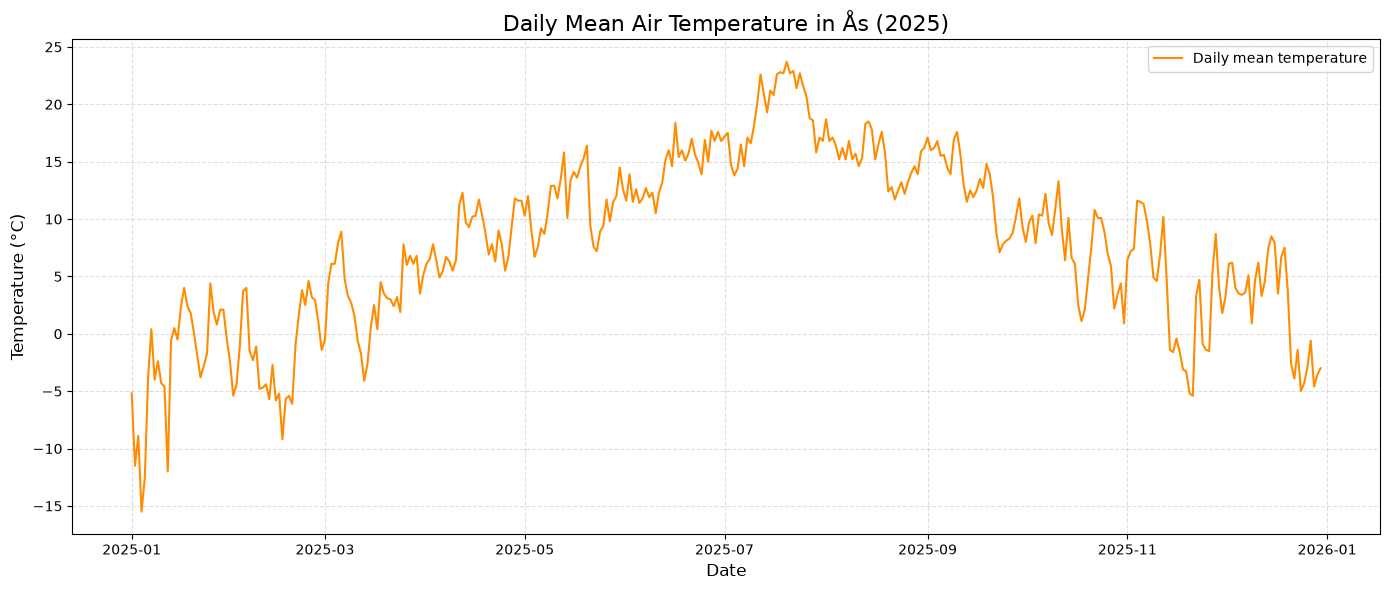

In [21]:
# Making a plot of the daily mean air temperature in Ås for 2025
plt.figure(figsize=(14, 6))

plt.plot(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["value"],
    color="darkorange",
    linewidth=1.5,
    label="Daily mean temperature"
)

plt.title("Daily Mean Air Temperature in Ås (2025)", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Temperature (°C)", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# Calculate summary statistics for 2025
temperature = df_2025["value"]

summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum"],
    "Temperature (°C)": [
        temperature.mean(),
        temperature.median(),
        temperature.min(),
        temperature.max()
    ]
})

# Display the summary table
display(
    summary.style.format("{:.2f}", subset=["Temperature (°C)"])
    .set_caption("Summary of daily mean air temperature in Ås (2025)"))

,Statistic,Temperature (°C)
0,Mean,7.90
1,Median,8.40
2,Minimum,-15.50
3,Maximum,23.70


Task 2: Precipitation

In [23]:

# Fetching precipitation data for 2025 from Frost API
df_precipitation_2025 = get_weather_data(
    station_id="SN17850",
    elements="sum(precipitation_amount P1D)",
    start_date="2025-01-01",
    end_date="2025-12-31",
)

# Keep the preferred time offset for daily precipitation
df_precipitation_2025 = df_precipitation_2025[
    df_precipitation_2025["timeOffset"] == "PT6H"
].copy()

display(df_precipitation_2025.head())

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,sourceId,referenceTime
1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-01T00:00:00.000Z
3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-02T00:00:00.000Z
5,sum(precipitation_amount P1D),0.1,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-03T00:00:00.000Z
7,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-04T00:00:00.000Z
9,sum(precipitation_amount P1D),0.0,mm,PT6H,P1D,0,C,2,0.0,SN17850:0,2025-01-05T00:00:00.000Z


According to the Frost API Data Clarifications, PT6H is the preferred time offset for daily precipitation. Therefore, we filter the dataset to keep only observations with this offset (https://frost.met.no/dataclarifications.html).

The dataset contains 364 daily observations. December 31, 2025, is missing from the data returned by Frost.

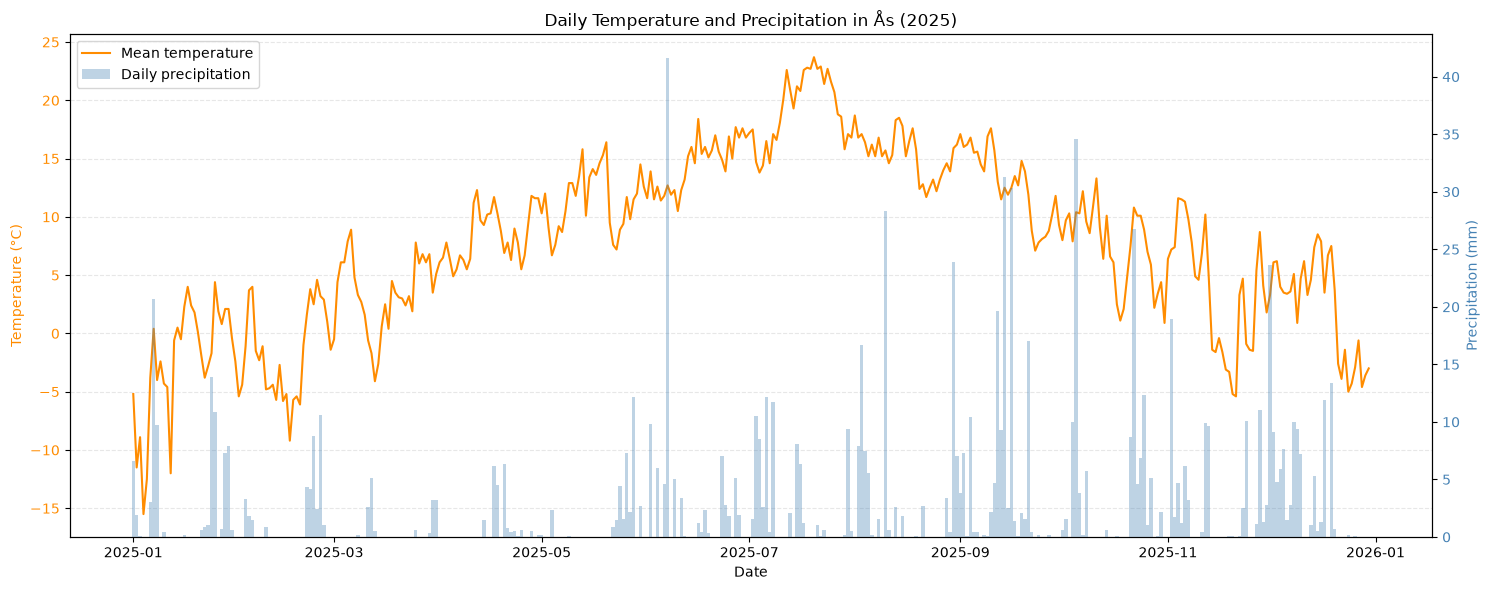

In [24]:
fig, ax1 = plt.subplots(figsize=(15, 6))

# Plot daily mean temperature as a line
ax1.plot(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["value"],
    color="darkorange",
    linewidth=1.5,
    label="Mean temperature",
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="darkorange")
ax1.tick_params(axis="y", labelcolor="darkorange")

# Create a second y-axis for precipitation
ax2 = ax1.twinx()

ax2.bar(
    pd.to_datetime(df_precipitation_2025["referenceTime"]),
    df_precipitation_2025["value"],
    color="steelblue",
    alpha=0.35,
    width=1.0,
    label="Daily precipitation",
)

ax2.set_ylabel("Precipitation (mm)", color="steelblue")
ax2.tick_params(axis="y", labelcolor="steelblue")
ax2.set_ylim(bottom=0)

# Add title and combined legend
ax1.set_title("Daily Temperature and Precipitation in Ås (2025)")

lines, labels = ax1.get_legend_handles_labels()
bars, bar_labels = ax2.get_legend_handles_labels()
ax1.legend(lines + bars, labels + bar_labels, loc="upper left")

ax1.grid(True, axis="y", linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()


Interpretation of the plot
We combined a line plot for temperature with a bar plot for precipitation to show how both variables change throughout 2025. We used two y-axes because temperature is measured in degrees Celsius (°C), while precipitation is measured in millimeters (mm).

One limitation of this visualization is that the two y-axes use different units and scales. Therefore, values at the same visual height are not directly comparable. For example, 5 mm of precipitation may appear at the same height as −12.5 °C, but these values are not equivalent. The plot is useful for comparing changes over time, but the visual relationship between the variables should be interpreted with care.

An alternative would be a scatter plot, with temperature on the x-axis and precipitation on the y-axis. This would be more suitable for investigating the relationship between the two variables. However, we chose the combined line and bar plot because our aim was to show how temperature and precipitation develop over the same period.

Task 3: Historical temperature data

**Husk og oppdatere samme time offset som i task 1_2025**

In [25]:
df_1925 = get_weather_data(
    station_id="SN17850",
    elements="mean(air_temperature P1D)",
    start_date="1925-01-01",
    end_date="1925-12-31",
)

display(df_1925.head())

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,level.levelType,level.unit,level.value,sourceId,referenceTime
0,mean(air_temperature P1D),1.3,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-01T00:00:00.000Z
1,mean(air_temperature P1D),4.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-02T00:00:00.000Z
2,mean(air_temperature P1D),2.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-03T00:00:00.000Z
3,mean(air_temperature P1D),0.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-04T00:00:00.000Z
4,mean(air_temperature P1D),-2.2,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-05T00:00:00.000Z


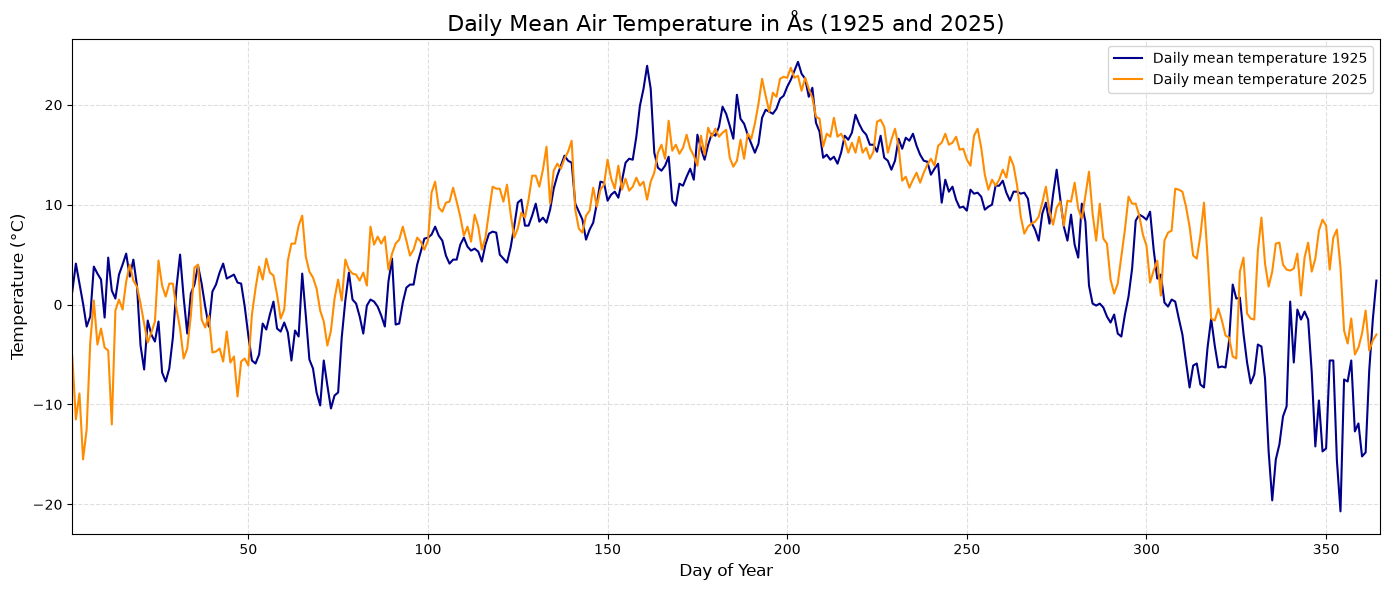

,Statistic,1925 (°C),2025 (°C)
0,Mean,5.31,7.90
1,Median,5.30,8.40
2,Min,-20.70,-15.50
3,Max,24.30,23.70


In [26]:
# Check that data is available
if df_1925.empty:
    print("No weather data found for the selected period.")

else:
    # Convert observation times to datetime
    df_1925["referenceTime"] = pd.to_datetime(df_1925["referenceTime"])
    df_2025["referenceTime"] = pd.to_datetime(df_2025["referenceTime"])

    # Sort observations by time
    df_1925 = df_1925.sort_values("referenceTime")
    df_2025 = df_2025.sort_values("referenceTime")

    # Extract day of year for both datasets
    df_1925["day_of_year"] = (df_1925["referenceTime"].dt.dayofyear)
    df_2025["day_of_year"] = (df_2025["referenceTime"].dt.dayofyear)

    # Create the plot
    plt.figure(figsize=(14, 6))
    plt.plot(
        df_1925["day_of_year"],
        df_1925["value"],
        color="darkblue",
        linewidth=1.5,
        label="Daily mean temperature 1925"
    )

    plt.plot(
        df_2025["day_of_year"],
        df_2025["value"],
        color="darkorange",
        linewidth=1.5,
        label="Daily mean temperature 2025"
    )

    # Add labels and title
    plt.xlabel("Day of Year", fontsize=12)
    plt.ylabel("Temperature (°C)", fontsize=12)
    plt.title("Daily Mean Air Temperature in Ås (1925 and 2025)", fontsize=16)

    # Improve layout
    plt.xlim(1, 365)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()

    # Display the plot
    plt.show()


# Calculate summary statistics for the year
summary_table = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Min", "Max"],
    "1925 (°C)": [
        df_1925["value"].mean(),
        df_1925["value"].median(),
        df_1925["value"].min(),
        df_1925["value"].max(),
    ],
    "2025 (°C)": [
        df_2025["value"].mean(),
        df_2025["value"].median(),
        df_2025["value"].min(),
        df_2025["value"].max(),
    ]
})

# Display summary table
display(
    summary_table.style.format("{:.2f}", subset=["1925 (°C)", "2025 (°C)"]).set_caption("Temperature (°C)"))


Task 4: Heatwaves

In [27]:
df_heatwaves = get_weather_data(
    station_id="SN17850",
    elements="max(air_temperature P1D)",
    start_date="2025-01-01",
    end_date="2025-12-31",
)

display(df_heatwaves.head())

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,level.levelType,level.unit,level.value,qualityCode,sourceId,referenceTime
0,max(air_temperature P1D),-3.4,degC,PT0H,P1D,0,C,1,height_above_ground,m,2,NaN,SN17850:0,2025-01-01T00:00:00.000Z
1,max(air_temperature P1D),-3.0,degC,PT18H,P1D,0,C,1,height_above_ground,m,2,0.0,SN17850:0,2025-01-01T00:00:00.000Z
2,max(air_temperature P1D),-5.2,degC,PT0H,P1D,0,C,1,height_above_ground,m,2,NaN,SN17850:0,2025-01-02T00:00:00.000Z
3,max(air_temperature P1D),-5.2,degC,PT18H,P1D,0,C,1,height_above_ground,m,2,0.0,SN17850:0,2025-01-02T00:00:00.000Z
4,max(air_temperature P1D),-1.4,degC,PT0H,P1D,0,C,1,height_above_ground,m,2,NaN,SN17850:0,2025-01-03T00:00:00.000Z


In [28]:
def summarize_heatwaves(
    df: pd.DataFrame,
    station_id: str,
    station_name: str,
    year: int,
    output_file: str,
    threshold: float = 27.0,
    min_days: int = 5,
) -> list[tuple[str, str]]:
    """
    Identify heatwaves and save the results to a YAML file.

    Args:
        df: DataFrame containing weather observations.
        station_id: Frost station ID.
        station_name: Weather station name.
        year: Year to analyze.
        output_file: Path to the output YAML file.
        threshold: Minimum daily maximum temperature in Celsius.
        min_days: Minimum number of consecutive days.

    Returns:
        A list of heatwave start and end dates.
    """
    dates = pd.date_range(
        start=f"{year}-01-01",
        end=f"{year}-12-31",
    )

    if df.empty:
        temperatures = pd.Series(index=dates, dtype=float)
    else:
        df = df.copy()

        df["date"] = (
            pd.to_datetime(df["referenceTime"], utc=True)
            .dt.tz_convert(None)
            .dt.normalize()
        )
        df["value"] = pd.to_numeric(df["value"], errors="coerce")

        temperatures = (
            df.groupby("date")["value"]
            .max()
            .reindex(dates)
        )

    hot_days = temperatures.ge(threshold).fillna(False)
    heatwaves = []
    start = None

    for date, is_hot in hot_days.items():
        if is_hot and start is None:
            start = date
        elif not is_hot and start is not None:
            if (date - start).days >= min_days:
                heatwaves.append((
                    start.strftime("%Y-%m-%d"),
                    (date - pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
                ))
            start = None

    if start is not None and (dates[-1] - start).days + 1 >= min_days:
        heatwaves.append((
            start.strftime("%Y-%m-%d"),
            dates[-1].strftime("%Y-%m-%d"),
        ))

    summary = {
        "dates": [f"{start} - {end}" for start, end in heatwaves],
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }

    with open(output_file, "w", encoding="utf-8") as file:
        yaml.safe_dump(
            summary,
            file,
            sort_keys=False,
            allow_unicode=True,
        )

    return heatwaves

In [29]:
heatwaves = summarize_heatwaves(
    df=df_heatwaves,
    station_id="SN17850",
    station_name="Ås",
    year=2025,
    output_file="heatwave_summary_2025.yml",
)

print(f"Number of heatwaves: {len(heatwaves)}")

Number of heatwaves: 1


In [30]:
with open(
    "heatwave_summary_2025.yml",
    "r",
    encoding="utf-8",
) as file:
    summary = yaml.safe_load(file)

print(summary)
print() 

print(f"Dates: {summary['dates']}")
print(f"Station: {summary['station_name']}")
print(f"Station ID: {summary['station_id']}")
print(f"Year: {summary['year']}")
print(f"Number of heatwaves: {len(summary['dates'])}")


{'dates': ['2025-07-16 - 2025-07-22'], 'station_id': 'SN17850', 'station_name': 'Ås', 'year': 2025}

Dates: ['2025-07-16 - 2025-07-22']
Station: Ås
Station ID: SN17850
Year: 2025
Number of heatwaves: 1


Task 5: Moving average temperature

In [31]:
def moving_average(temperature, window=7):
    """
    Calculate the moving average of temperature.

    Args:
        temperature: A pandas Series containing daily temperatures.
        window: Number of days used to calculate the moving average.

    Returns:
        A pandas Series containing the moving average.
    """
    return temperature.rolling(window=window).mean()


In [32]:
# Calculate the 7-day moving average
df_2025["moving_average"] = moving_average(
    df_2025["value"],
    window=7
)

# Display the first rows
display(df_2025[["referenceTime", "value", "moving_average"]].head(10))

,referenceTime,value,moving_average
0,2025-01-01 00:00:00+00:00,-5.2,NaN
2,2025-01-02 00:00:00+00:00,-11.5,NaN
4,2025-01-03 00:00:00+00:00,-8.9,NaN
6,2025-01-04 00:00:00+00:00,-15.5,NaN
8,2025-01-05 00:00:00+00:00,-12.5,NaN
10,2025-01-06 00:00:00+00:00,-3.8,NaN
12,2025-01-07 00:00:00+00:00,0.4,-8.142857
14,2025-01-08 00:00:00+00:00,-4.0,-7.971429
16,2025-01-09 00:00:00+00:00,-2.4,-6.671429
18,2025-01-10 00:00:00+00:00,-4.3,-6.014286


In [33]:
df_2025["referenceTime"] = pd.to_datetime(df_2025["referenceTime"])
df_2025 = df_2025.sort_values("referenceTime").reset_index(drop=True)

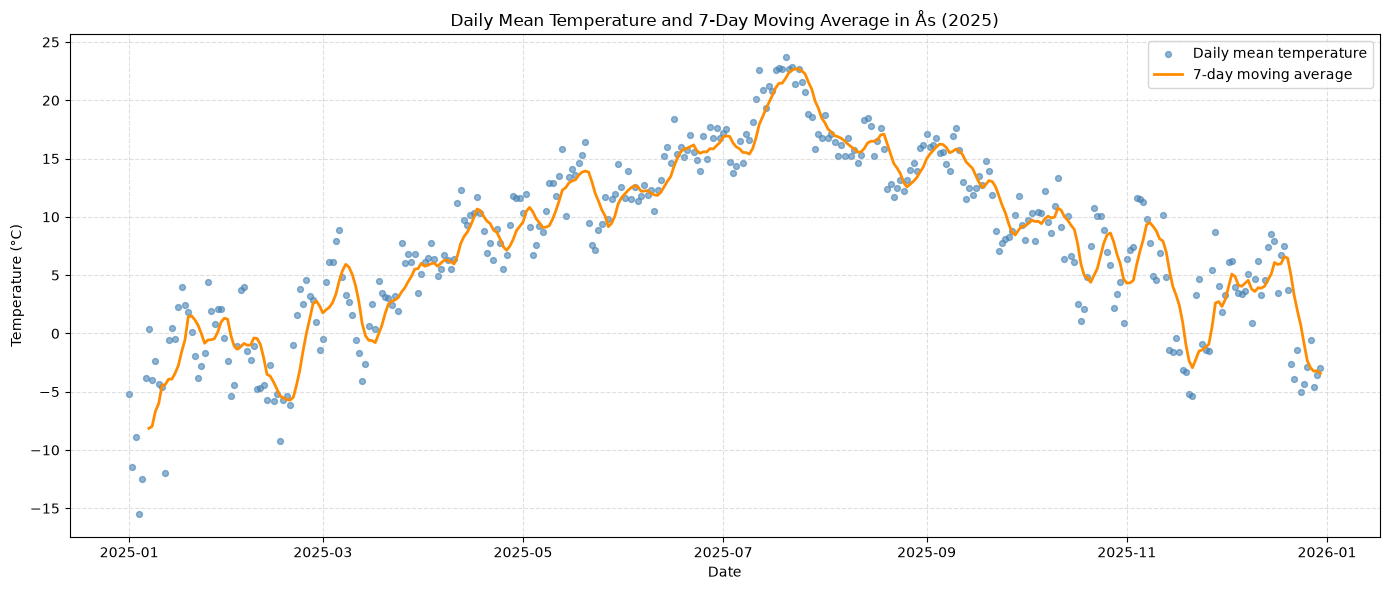

In [34]:
plt.figure(figsize=(14, 6))

# Plot daily temperatures as points
plt.scatter(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["value"],
    color="steelblue",
    s=18,
    alpha=0.6,
    label="Daily mean temperature"
)

# Plot the 7-day moving average as a line
plt.plot(
    pd.to_datetime(df_2025["referenceTime"]),
    df_2025["moving_average"],
    color="darkorange",
    linewidth=2,
    label="7-day moving average"
)

plt.title("Daily Mean Temperature and 7-Day Moving Average in Ås (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


Interpretation of the plot

The plot shows the daily mean temperature together with a 7-day moving average. The daily temperatures are shown as points, while the moving average is shown as a line.

The moving average is calculated using the temperatures from seven consecutive observations. It smooths out day-to-day changes and makes it easier to identify overall temperature trends. The first six observations do not have a moving average because there are not yet seven observations available.

By comparing the daily temperatures with the moving average, we can see both the day-to-day variations and the broader temperature trends throughout the year.